Good apple rotten apple detection.

**Dataset link:** https://universe.roboflow.com/universidadde-de-trsosmontes-e-alto-douro/rotten-apples-detection

In [1]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="fjJRUaXvvrDfUOVt7cAl")
project = rf.workspace("universidadde-de-trsosmontes-e-alto-douro").project("rotten-apples-detection")
version = project.version(5)
dataset = version.download("folder")


loading Roboflow workspace...
loading Roboflow project...


In [2]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import matplotlib.pyplot as plt
import os

In [3]:
# setup basic pats
base_dir='/content/Rotten-apples-detection-5'
train_dir=os.path.join(base_dir, 'train')
valid_dir=os.path.join(base_dir, 'valid')

In [4]:
# 1. load and preprocess data
image_size=224
batch_size=16

In [5]:
train_datagen=ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True)
valid_datagen=ImageDataGenerator(rescale=1./255)

To delete a unwanted folder

In [6]:
# go to that folder
%cd '/content/Rotten-apples-detection-5/train'

/content/Rotten-apples-detection-5/train


In [7]:
!ls

'Good Apple'  'Rotten Apple'


In [8]:
!rm -rf 'Good Apple Rotten Apple'

In [9]:
!ls

'Good Apple'  'Rotten Apple'


In [10]:
train_gen=train_datagen.flow_from_directory(
    train_dir, target_size=(image_size, image_size), batch_size=batch_size, class_mode='categorical')
valid_gen=valid_datagen.flow_from_directory(
    valid_dir, target_size=(image_size, image_size), batch_size=batch_size, class_mode='categorical')

Found 777 images belonging to 2 classes.
Found 100 images belonging to 2 classes.


In [11]:
# 2. load vgg16 base model
base_model=VGG16(weights='imagenet', include_top=False, input_shape=(image_size, image_size, 3))
base_model.trainable= False #freeze convolutional base

# 3. add custom classification head
x=base_model.output
x=Flatten()(x)
x=Dense(128, activation='relu')(x)
x=Dropout(0.5)(x)
prediction=Dense(train_gen.num_classes, activation='sigmoid')(x)

In [20]:
model=Model(inputs=base_model.input, outputs=prediction)

In [21]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,926,338 (68.38 MB)

 Trainable params: 3,211,650 (12.25 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [22]:
# model compilation
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [15]:
# train model
history=model.fit(train_gen, epochs=5, validation_data=valid_gen)

Epoch 1/5
49/49 ━━━━━━━━━━━━━━━━━━━━ 35s 463ms/step - accuracy: 0.6821 - loss: 0.9503 - val_accuracy: 0.9500 - val_loss: 0.1630
Epoch 2/5
49/49 ━━━━━━━━━━━━━━━━━━━━ 13s 272ms/step - accuracy: 0.7967 - loss: 0.4363 - val_accuracy: 0.9200 - val_loss: 0.1990
Epoch 3/5
49/49 ━━━━━━━━━━━━━━━━━━━━ 14s 275ms/step - accuracy: 0.8456 - loss: 0.3744 - val_accuracy: 0.9600 - val_loss: 0.1673
Epoch 4/5
49/49 ━━━━━━━━━━━━━━━━━━━━ 14s 284ms/step - accuracy: 0.8546 - loss: 0.2971 - val_accuracy: 0.9700 - val_loss: 0.0896
Epoch 5/5
49/49 ━━━━━━━━━━━━━━━━━━━━ 14s 275ms/step - accuracy: 0.8623 - loss: 0.3024 - val_accuracy: 0.9600 - val_loss: 0.1211


In [16]:
loss, acc=model.evaluate(valid_gen)
print(f'Test accuracy: {acc:.2f}')

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 0.9600 - loss: 0.1211 
Test accuracy: 0.96


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 696ms/step


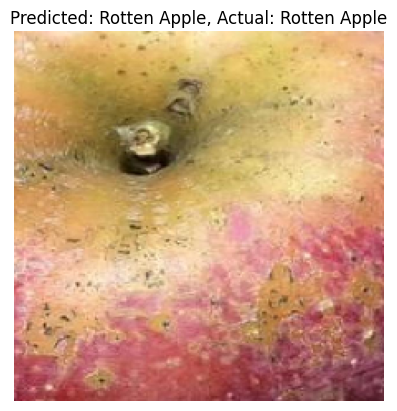

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step


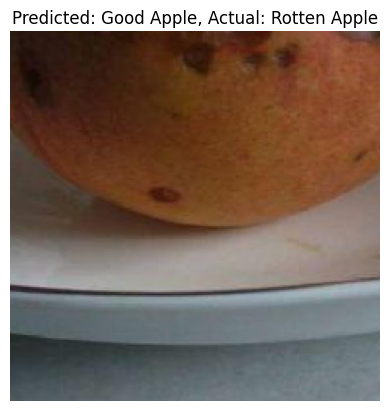

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step


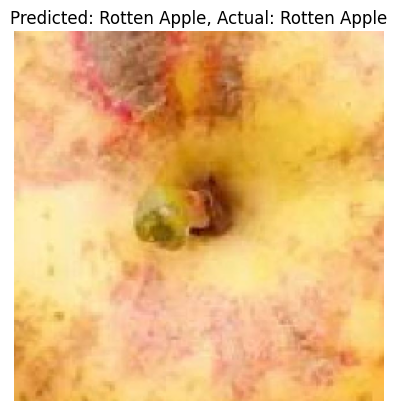

In [17]:
# inference : predict and visualize some test images
class_labels=list(valid_gen.class_indices.keys())
def plot_prediction(generator, model, num=5):
  for i in range(num):
    img, lbl=next(generator)
    pred=model.predict(img)
    plt.imshow(img[0])

    plt.title(f"Predicted: {class_labels[np.argmax(pred[0])]}, Actual: {class_labels[np.argmax(lbl[0])]}")
    plt.axis('off')
    plt.show()

plot_prediction(valid_gen, model, num=3)